# 🏥 Denmark Cancer Patient Analysis
**An exploratory data analysis (EDA) project** · Python · pandas · matplotlib · seaborn · SciPy

## 1. Business problem
A hospital analytics team wants to understand **who the patients are** and **what is linked to survival time and relapse**, so clinicians can flag patients who may need closer follow-up.

## Questions we will answer
| # | Question |
|---|---|
| Q1 | What does the patient population look like? |
| Q2 | How is age distributed, and how does it relate to cancer type and survival? |
| Q3 | Does BMI relate to survival or relapse? |
| Q4 | How long do patients survive, and what is linked to it? |
| Q5 | Are the differences we see **real** or just random noise? *(statistical testing)* |
| Q6 | How long do patients wait for treatment, and does the wait matter? |
| Q7 | Which patients have short survival (under 24 months)? |

**How to read this notebook:** each section = *question → chart → what it means*. Chart titles state the takeaway, so you can skim just the pictures and still follow the story.

## 2. Setup

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# One colour palette used everywhere = a consistent, professional look
NAVY, TEAL, AMBER, CORAL, GREY = '#14213D', '#2A9D8F', '#E9C46A', '#E76F51', '#8D99AE'
STAGE_COL = ['#BFE3DE', '#6DBFB3', AMBER, CORAL]          # light -> severe
SURV_COL  = {'Short': CORAL, 'Medium': AMBER, 'Long': TEAL}

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': .25, 'axes.axisbelow': True,
    'axes.edgecolor': '#555', 'text.color': NAVY, 'axes.labelcolor': NAVY,
})

IMG = Path('../images'); IMG.mkdir(exist_ok=True)
def save(name):
    plt.savefig(IMG / name, facecolor='white'); plt.show()

# --- small statistics helpers ---
def mean_ci(x, conf=.95):
    """Mean and its 95% confidence interval."""
    x = np.asarray(x, float); m = x.mean()
    h = stats.sem(x) * stats.t.ppf((1 + conf) / 2, len(x) - 1)
    return m, m - h, m + h

def wilson(k, n, z=1.96):
    """Proportion and its 95% (Wilson) confidence interval."""
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return p, c - h, c + h

## 3. Load and inspect the raw data
Before any analysis, we always look at the data from several angles.

### 3.1 Load the data

In [2]:
df = pd.read_csv('../data/raw/cancer_data_denmark.csv')
print('Data loaded successfully')

Data loaded successfully


### 3.2 `head()`: first 5 rows

In [3]:
df.head()

,Patient_ID,Age,Gender,Cancer_Type,Stage,Diagnosis_Date,Treatment_Type,Treatment_Start_Date,Treatment_End_Date,Tumor_Size_cm,Lymph_Nodes_Examined,Smoking_Status,BMI,Family_History,Survival_Months,Relapse,Occupation,Income_Level,Followup_Date
0,1,69,Male,Leukemia,III,26-06-2015,Radiation,19-11-2015,24-04-2020,9.53,10.0,Current,19.4,Yes,83,No,Office Worker,Low,13-12-2022
1,2,41,Male,Lung,I,05-03-2016,Hormone Therapy,01-07-2022,16-12-2023,6.68,1.0,Never,26.6,No,108,Yes,Healthcare,High,15-08-2024
2,3,47,Female,Prostate,II,17-09-2017,Radiation,09-05-2022,10-06-2023,NaN,0.0,Never,26.2,No,108,No,Retired,Medium,16-06-2024
3,4,66,Male,Skin,I,07-03-2018,Immunotherapy,19-02-2019,03-06-2020,5.49,9.0,Current,15.4,Yes,108,Yes,Office Worker,High,27-04-2024
4,5,72,Male,Breast,II,09-11-2019,Chemotherapy,17-11-2019,16-03-2023,9.84,2.0,Former,19.2,Yes,39,No,Manual Labor,Low,22-05-2023


### 3.3 `tail()`: last 5 rows

In [4]:
df.tail()

,Patient_ID,Age,Gender,Cancer_Type,Stage,Diagnosis_Date,Treatment_Type,Treatment_Start_Date,Treatment_End_Date,Tumor_Size_cm,Lymph_Nodes_Examined,Smoking_Status,BMI,Family_History,Survival_Months,Relapse,Occupation,Income_Level,Followup_Date
1209,1210,51,Female,Colon,III,01-05-2025,Immunotherapy,17-05-2025,17-05-2025,10.00,14.0,Never,23.8,Yes,86,Yes,Unemployed,Medium,20-05-2025
1210,1211,41,Female,Breast,III,08-07-2022,Chemotherapy,15-02-2025,07-03-2025,2.81,11.0,Never,21.1,No,34,No,Healthcare,Medium,09-05-2025
1211,1212,28,Male,Lung,III,04-10-2017,Surgery,26-02-2020,24-08-2024,6.68,2.0,Never,33.0,Yes,42,No,Manual Labor,Medium,16-09-2024
1212,1213,45,Male,Lung,III,25-12-2016,Immunotherapy,25-11-2021,24-01-2025,5.10,13.0,Never,28.3,No,118,Yes,Office Worker,Low,31-01-2025
1213,1214,70,Female,Lung,II,08-03-2020,Chemotherapy,07-03-2025,15-04-2025,4.31,3.0,Current,30.2,No,97,No,Unemployed,Low,05-05-2025


### 3.4 `sample()`: 5 random rows
`random_state=42` makes the "random" rows the same every time you run it.

In [5]:
df.sample(5, random_state=42)

,Patient_ID,Age,Gender,Cancer_Type,Stage,Diagnosis_Date,Treatment_Type,Treatment_Start_Date,Treatment_End_Date,Tumor_Size_cm,Lymph_Nodes_Examined,Smoking_Status,BMI,Family_History,Survival_Months,Relapse,Occupation,Income_Level,Followup_Date
739,740,27,Male,Colon,III,22-07-2021,Hormone Therapy,05-06-2022,12-09-2023,3.60,16.0,Never,26.1,No,119,No,Office Worker,Medium,19-02-2025
788,789,51,Female,Breast,I,13-01-2024,Radiation,11-11-2024,05-01-2025,0.79,8.0,Never,31.2,Yes,85,Yes,Manual Labor,Medium,29-04-2025
43,44,58,Male,Lung,I,10-05-2022,Chemotherapy,07-02-2025,12-03-2025,2.17,3.0,Never,21.0,Yes,14,Yes,Healthcare,Medium,16-05-2025
155,156,68,Male,Skin,IV,13-01-2025,Immunotherapy,13-04-2025,11-05-2025,7.50,7.0,Former,31.5,Yes,86,Yes,Unemployed,Medium,19-05-2025
494,495,54,Male,Skin,II,13-08-2019,Surgery,29-01-2023,07-01-2024,0.55,7.0,Never,27.3,Yes,1,No,Healthcare,Medium,13-05-2024


### 3.5 `shape`: number of rows and columns

In [6]:
print('Shape:', df.shape)
print('Rows   :', df.shape[0])
print('Columns:', df.shape[1])

Shape: (1214, 19)
Rows   : 1214
Columns: 19


### 3.6 `columns`: column names

In [7]:
print(df.columns.tolist())

['Patient_ID', 'Age', 'Gender', 'Cancer_Type', 'Stage', 'Diagnosis_Date', 'Treatment_Type', 'Treatment_Start_Date', 'Treatment_End_Date', 'Tumor_Size_cm', 'Lymph_Nodes_Examined', 'Smoking_Status', 'BMI', 'Family_History', 'Survival_Months', 'Relapse', 'Occupation', 'Income_Level', 'Followup_Date']


### 3.7 `dtypes`: data type of each column

In [8]:
df.dtypes

Patient_ID                int64
Age                       int64
Gender                      str
Cancer_Type                 str
Stage                       str
Diagnosis_Date              str
Treatment_Type              str
Treatment_Start_Date        str
Treatment_End_Date          str
Tumor_Size_cm           float64
Lymph_Nodes_Examined    float64
Smoking_Status              str
BMI                     float64
Family_History              str
Survival_Months           int64
Relapse                     str
Occupation                  str
Income_Level                str
Followup_Date               str
dtype: object

### 3.8 `info()`: types, non-null counts and memory

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1214 entries, 0 to 1213
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Patient_ID            1214 non-null   int64  
 1   Age                   1214 non-null   int64  
 2   Gender                1214 non-null   str    
 3   Cancer_Type           1214 non-null   str    
 4   Stage                 1214 non-null   str    
 5   Diagnosis_Date        1214 non-null   str    
 6   Treatment_Type        1213 non-null   str    
 7   Treatment_Start_Date  1213 non-null   str    
 8   Treatment_End_Date    1211 non-null   str    
 9   Tumor_Size_cm         1213 non-null   float64
 10  Lymph_Nodes_Examined  1210 non-null   float64
 11  Smoking_Status        1213 non-null   str    
 12  BMI                   1213 non-null   float64
 13  Family_History        1214 non-null   str    
 14  Survival_Months       1214 non-null   int64  
 15  Relapse               1214 non-n

### 3.9 `describe()`: summary statistics of all columns
`include='all'` shows numeric columns (mean, std, min, max...) **and** text columns (unique, top, freq).

In [10]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Patient_ID,1214.0,NaN,NaN,NaN,607.5,350.595921,1.0,304.25,607.5,910.75,1214.0
Age,1214.0,NaN,NaN,NaN,52.7743,20.980542,18.0,34.0,52.0,71.0,89.0
Gender,1214,2,Male,635,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cancer_Type,1214,6,Leukemia,226,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Stage,1214,4,IV,317,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Diagnosis_Date,1214,1026,13-01-2019,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Treatment_Type,1213,5,Surgery,257,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Treatment_Start_Date,1213,908,18-05-2025,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Treatment_End_Date,1211,698,22-05-2025,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tumor_Size_cm,1213.0,NaN,NaN,NaN,5.227955,2.80163,0.51,2.78,5.22,7.61,10.0


### 3.10 Missing values and duplicates

In [11]:
miss = df.isna().sum()
print('Missing values per column:\n', miss[miss > 0].to_string())
print('\nDuplicate rows:', df.duplicated().sum())

Missing values per column:
 Treatment_Type          1
Treatment_Start_Date    1
Treatment_End_Date      3
Tumor_Size_cm           1
Lymph_Nodes_Examined    4
Smoking_Status          1
BMI                     1
Occupation              2

Duplicate rows: 0


**What we found:** very few missing values (1–4 per column), no duplicates, and all four date columns are stored as **text** (`dd-mm-yyyy`). We fix these next.

## 4. Clean the data
Rows with missing values are **removed, not filled**, so every remaining value is real recorded data.

In [12]:
clean = df.drop_duplicates().copy()
n_before = len(clean)
clean = clean.dropna()
print(f'Rows removed because of missing values: {n_before - len(clean)}')

cat_cols = ['Gender','Cancer_Type','Stage','Treatment_Type','Smoking_Status',
            'Family_History','Relapse','Occupation','Income_Level']
for c in cat_cols:
    clean[c] = clean[c].str.strip()

for c in ['Diagnosis_Date','Treatment_Start_Date','Treatment_End_Date','Followup_Date']:
    clean[c] = pd.to_datetime(clean[c], format='%d-%m-%Y')
clean['Lymph_Nodes_Examined'] = clean['Lymph_Nodes_Examined'].astype(int)
clean['Stage'] = pd.Categorical(clean['Stage'], ['I','II','III','IV'], ordered=True)

Rows removed because of missing values: 14


### Data-quality checks
Cleaning is not only about missing values. We also test whether the data **makes sense**.

In [13]:
delay    = (clean.Treatment_Start_Date - clean.Diagnosis_Date).dt.days
duration = (clean.Treatment_End_Date - clean.Treatment_Start_Date).dt.days
follow_m = (clean.Followup_Date - clean.Diagnosis_Date).dt.days / 30.44

checks = pd.Series({
    'Treatment starts BEFORE diagnosis':            (delay < 0).sum(),
    'Treatment ends BEFORE it starts':              (duration < 0).sum(),
    'Age outside 18-100':                           (~clean.Age.between(18, 100)).sum(),
    'BMI outside 10-60':                            (~clean.BMI.between(10, 60)).sum(),
    'Tumour size <= 0':                             (clean.Tumor_Size_cm <= 0).sum(),
    'Survival longer than diagnosis→follow-up gap': (follow_m < clean.Survival_Months).sum(),
})
print(checks.to_string())

Treatment starts BEFORE diagnosis                 0
Treatment ends BEFORE it starts                   0
Age outside 18-100                                0
BMI outside 10-60                                 0
Tumour size <= 0                                  0
Survival longer than diagnosis→follow-up gap    698


**Reading the result:** the first five checks pass (all 0). The last one flags a **data-quality warning**: for more than half of patients, `Survival_Months` is longer than the time between diagnosis and the last follow-up. In a real project we would ask the data owner how survival was measured. Here we continue, but we keep this limitation in mind. *Finding an issue like this is a good result, not a failure.*

## 5. Feature engineering (new columns)
| New column | Based on | Rule |
|---|---|---|
| `Age_Group` | Age | 18-30, 31-45, 46-60, 61-75, 76+ |
| `BMI_Category` | BMI | Underweight <18.5 · Normal 18.5–24.9 · Overweight 25–29.9 · Obese 30+ |
| `Survival_Category` | Survival_Months | Short <24 · Medium 24–59 · Long 60+ months |
| `Treatment_Delay_Days` | dates | Treatment start − diagnosis |
| `Treatment_Duration_Days` | dates | Treatment end − treatment start |
| `Diagnosis_Year` | date | Year of diagnosis |
| `Relapse_Flag` | Relapse | 1 = Yes, 0 = No (lets us average it into a *rate*) |

In [14]:
clean['Age_Group'] = pd.cut(clean.Age, [17,30,45,60,75,120], labels=['18-30','31-45','46-60','61-75','76+'])
clean['BMI_Category'] = pd.cut(clean.BMI, [0,18.5,25,30,100], right=False,
                               labels=['Underweight','Normal','Overweight','Obese'])
clean['Survival_Category'] = pd.cut(clean.Survival_Months, [0,24,60,1000], right=False,
                                    labels=['Short','Medium','Long'])
clean['Treatment_Delay_Days']    = delay
clean['Treatment_Duration_Days'] = duration
clean['Diagnosis_Year'] = clean.Diagnosis_Date.dt.year
clean['Relapse_Flag']   = (clean.Relapse == 'Yes').astype(int)

clean.to_csv('../data/processed/cancer_data_denmark_clean.csv', index=False)
print('Clean shape:', clean.shape)
clean[['Patient_ID','Age','Age_Group','BMI','BMI_Category','Survival_Months',
       'Survival_Category','Treatment_Delay_Days']].head()

Clean shape: (1200, 26)


,Patient_ID,Age,Age_Group,BMI,BMI_Category,Survival_Months,Survival_Category,Treatment_Delay_Days
0,1,69,61-75,19.4,Normal,83,Long,146
1,2,41,31-45,26.6,Overweight,108,Long,2309
3,4,66,61-75,15.4,Underweight,108,Long,349
4,5,72,61-75,19.2,Normal,39,Medium,8
5,6,35,31-45,26.9,Overweight,9,Short,420


## 6. Exploratory analysis
### Q1. What does the patient population look like?

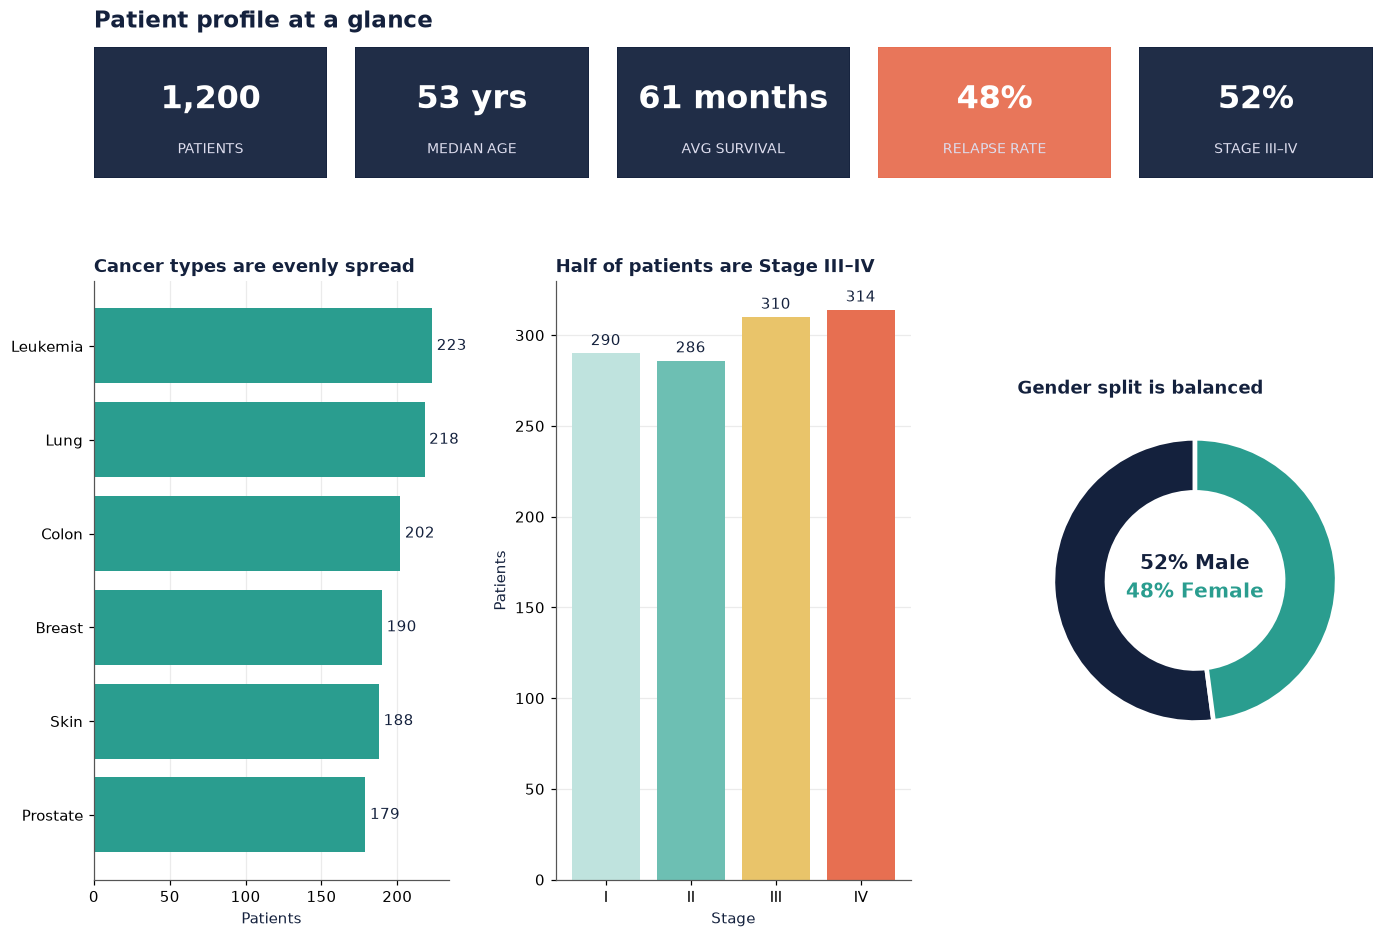

In [15]:
fig = plt.figure(figsize=(15, 8.5))
# KPI strip
kpis = [('Patients', f'{len(clean):,}'),
        ('Median age', f'{clean.Age.median():.0f} yrs'),
        ('Avg survival', f'{clean.Survival_Months.mean():.0f} months'),
        ('Relapse rate', f'{clean.Relapse_Flag.mean():.0%}'),
        ('Stage III–IV', f'{(clean.Stage >= "III").mean():.0%}')]
gk = fig.add_gridspec(1, 5, top=.97, bottom=.83, wspace=.12)
for i, (lab, val) in enumerate(kpis):
    ax = fig.add_subplot(gk[i]); ax.axis('off')
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color=NAVY if i != 3 else CORAL, alpha=.95))
    ax.text(.5, .60, val, ha='center', va='center', color='white', fontsize=21, fontweight='bold', transform=ax.transAxes)
    ax.text(.5, .22, lab.upper(), ha='center', va='center', color='#DDE', fontsize=9, transform=ax.transAxes)
fig.suptitle('Patient profile at a glance', x=.125, y=1.01, ha='left', fontsize=15, fontweight='bold')

g = fig.add_gridspec(1, 3, top=.72, bottom=.08, wspace=.3)
ax = fig.add_subplot(g[0])
ct = clean.Cancer_Type.value_counts().sort_values()
ax.barh(ct.index, ct.values, color=TEAL); ax.bar_label(ax.containers[0], padding=3)
ax.set_title('Cancer types are evenly spread'); ax.set_xlabel('Patients'); ax.grid(axis='y', visible=False)

ax = fig.add_subplot(g[1])
st = clean.Stage.value_counts().sort_index()
ax.bar(st.index.astype(str), st.values, color=STAGE_COL); ax.bar_label(ax.containers[0], padding=3)
ax.set_title('Half of patients are Stage III–IV'); ax.set_xlabel('Stage'); ax.set_ylabel('Patients'); ax.grid(axis='x', visible=False)

ax = fig.add_subplot(g[2])
gd = clean.Gender.value_counts()
ax.pie(gd, colors=[NAVY, TEAL], startangle=90, wedgeprops=dict(width=.38, edgecolor='white', linewidth=3))
ax.text(0, .08, f'{gd.iloc[0]/len(clean):.0%} {gd.index[0]}', ha='center', fontsize=13, fontweight='bold', color=NAVY)
ax.text(0, -.12, f'{gd.iloc[1]/len(clean):.0%} {gd.index[1]}', ha='center', fontsize=13, fontweight='bold', color=TEAL)
ax.set_title('Gender split is balanced')
save('01_overall_profile.png')

### Q2. How is age distributed?

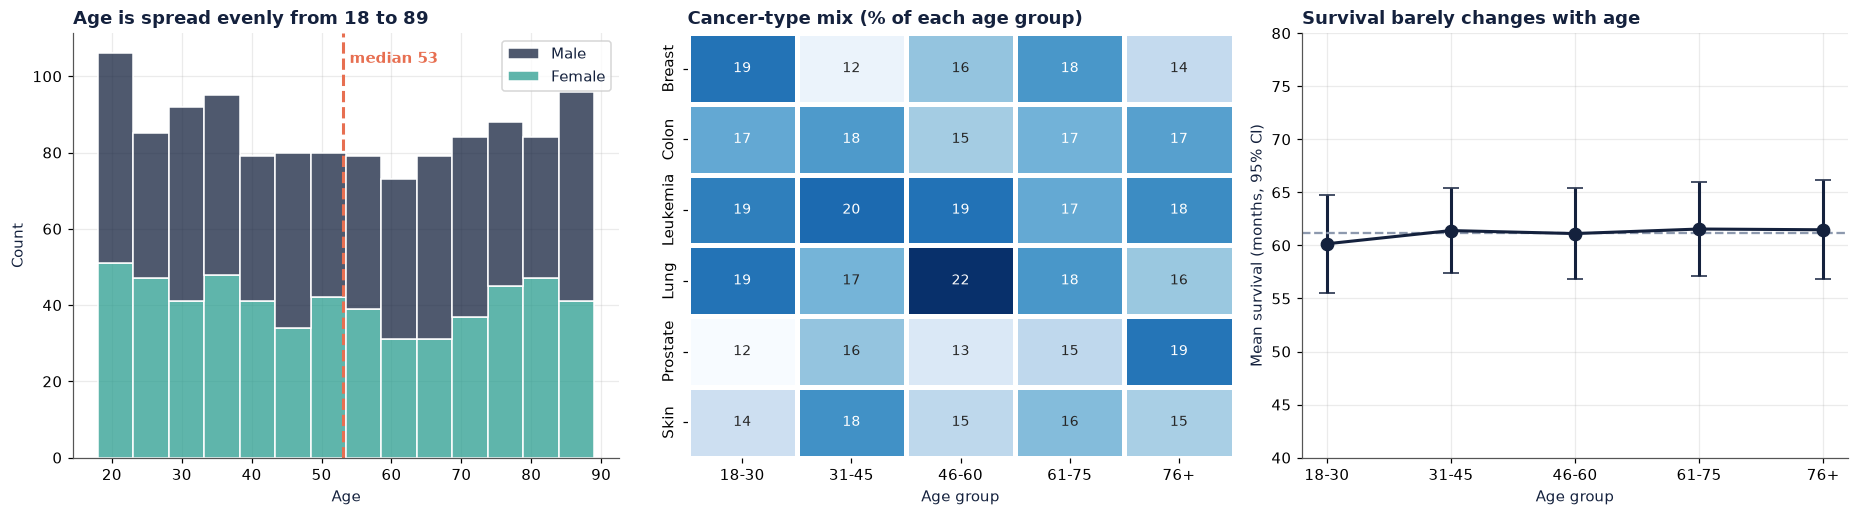

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
sns.histplot(data=clean, x='Age', hue='Gender', multiple='stack', bins=14,
             palette=[NAVY, TEAL], edgecolor='white', ax=ax[0])
ax[0].axvline(clean.Age.median(), color=CORAL, ls='--', lw=2)
ax[0].text(clean.Age.median() + 1, ax[0].get_ylim()[1] * .93, f'median {clean.Age.median():.0f}', color=CORAL, fontweight='bold')
ax[0].set_title('Age is spread evenly from 18 to 89'); ax[0].get_legend().set_title('')

mix = pd.crosstab(clean.Cancer_Type, clean.Age_Group, normalize='columns') * 100
sns.heatmap(mix, annot=True, fmt='.0f', cmap='Blues', cbar=False, linewidths=2, linecolor='white',
            annot_kws={'fontsize': 9}, ax=ax[1])
ax[1].set_title('Cancer-type mix (% of each age group)'); ax[1].set_xlabel('Age group'); ax[1].set_ylabel('')

rows = [(g, *mean_ci(x.Survival_Months)) for g, x in clean.groupby('Age_Group', observed=True)]
a = pd.DataFrame(rows, columns=['g', 'm', 'lo', 'hi'])
ax[2].errorbar(a.g, a.m, yerr=[a.m - a.lo, a.hi - a.m], fmt='o-', color=NAVY, capsize=5, lw=2, ms=8)
ax[2].axhline(clean.Survival_Months.mean(), color=GREY, ls='--')
ax[2].set_ylim(40, 80); ax[2].set_title('Survival barely changes with age'); ax[2].set_ylabel('Mean survival (months, 95% CI)')
ax[2].set_xlabel('Age group')
plt.tight_layout(); save('02_age_analysis.png')

### Q3. Does BMI relate to survival or relapse?
We add **95% confidence intervals** (the thin black lines). They show how uncertain each number is. If the intervals overlap heavily, the difference may be just noise.

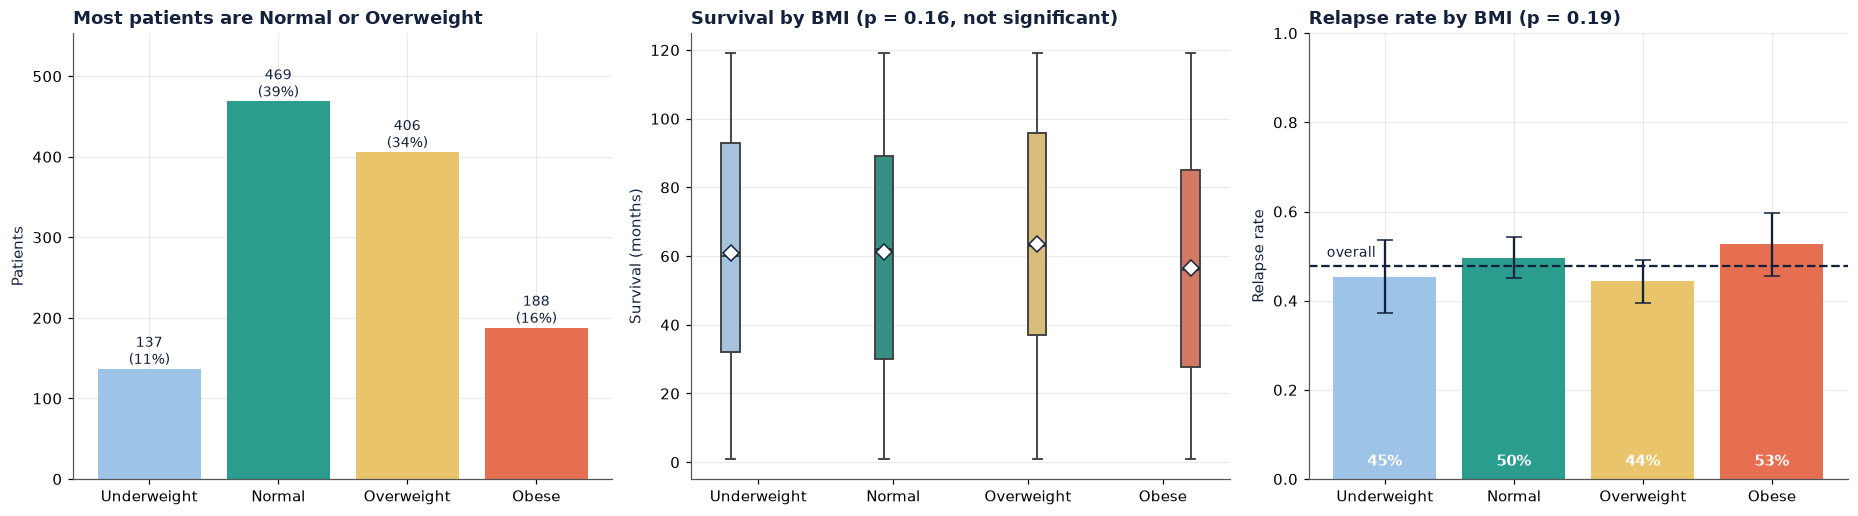

In [17]:
order = ['Underweight', 'Normal', 'Overweight', 'Obese']
BMI_COL = ['#9DC3E6', TEAL, AMBER, CORAL]
p_bmi_s = stats.kruskal(*[x.Survival_Months for _, x in clean.groupby('BMI_Category', observed=True)]).pvalue
p_bmi_r = stats.chi2_contingency(pd.crosstab(clean.BMI_Category, clean.Relapse))[1]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
cnt = clean.BMI_Category.value_counts().reindex(order)
ax[0].bar(order, cnt.values, color=BMI_COL)
for i, v in enumerate(cnt.values): ax[0].text(i, v + 6, f'{v}\n({v/len(clean):.0%})', ha='center', fontsize=9)
ax[0].set_ylim(0, cnt.max() * 1.18); ax[0].set_title('Most patients are Normal or Overweight'); ax[0].set_ylabel('Patients')

sns.boxplot(data=clean, x='BMI_Category', y='Survival_Months', order=order, palette=BMI_COL, hue='BMI_Category',
            legend=False, showmeans=True, width=.55, linewidth=1.2, fliersize=2,
            meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor=NAVY, markersize=7), ax=ax[1])
ax[1].set_title(f'Survival by BMI (p = {p_bmi_s:.2f}, not significant)'); ax[1].set_ylabel('Survival (months)'); ax[1].set_xlabel('')

r = [(c, *wilson(x.Relapse_Flag.sum(), len(x))) for c, x in clean.groupby('BMI_Category', observed=True)]
r = pd.DataFrame(r, columns=['c', 'p', 'lo', 'hi']).set_index('c').loc[order]
ax[2].bar(order, r.p, color=BMI_COL, yerr=[r.p - r.lo, r.hi - r.p], capsize=5, error_kw=dict(ecolor=NAVY))
ax[2].axhline(clean.Relapse_Flag.mean(), color=NAVY, ls='--'); ax[2].text(-.45, clean.Relapse_Flag.mean() + .02, 'overall', ha='left', fontsize=9)
for i, v in enumerate(r.p): ax[2].text(i, .03, f'{v:.0%}', ha='center', color='white', fontweight='bold')
ax[2].set_ylim(0, 1); ax[2].set_title(f'Relapse rate by BMI (p = {p_bmi_r:.2f})'); ax[2].set_ylabel('Relapse rate')
plt.tight_layout(); save('03_bmi_analysis.png')

### Q4. How long do patients survive?

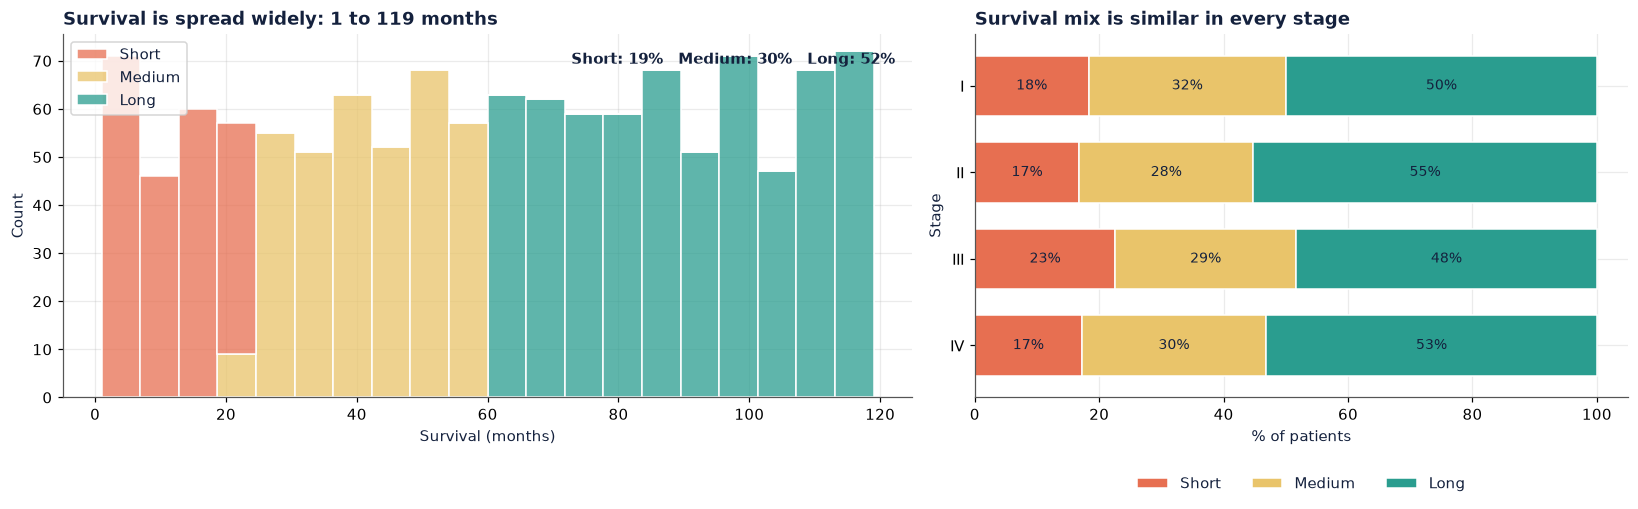

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [1.3, 1]})
sns.histplot(data=clean, x='Survival_Months', hue='Survival_Category', hue_order=['Short', 'Medium', 'Long'],
             palette=SURV_COL, binwidth=6, multiple='stack', edgecolor='white', ax=ax[0])
sh = clean.Survival_Category.value_counts(normalize=True)
ax[0].set_title('Survival is spread widely: 1 to 119 months'); ax[0].set_xlabel('Survival (months)')
ax[0].get_legend().set_title('')
ax[0].text(.98, .95, '   '.join(f'{k}: {sh[k]:.0%}' for k in ['Short', 'Medium', 'Long']),
           transform=ax[0].transAxes, ha='right', va='top', fontsize=10, fontweight='bold')

sc = pd.crosstab(clean.Stage, clean.Survival_Category, normalize='index')[['Short', 'Medium', 'Long']] * 100
sc.plot(kind='barh', stacked=True, color=[SURV_COL[c] for c in sc.columns], ax=ax[1], width=.7, edgecolor='white')
for c in ax[1].containers: ax[1].bar_label(c, fmt='%.0f%%', label_type='center', color=NAVY, fontsize=9)
ax[1].invert_yaxis(); ax[1].set_title('Survival mix is similar in every stage'); ax[1].set_xlabel('% of patients')
ax[1].set_ylabel('Stage'); ax[1].legend(ncol=3, loc='upper center', bbox_to_anchor=(.5, -.18), frameon=False)
plt.tight_layout(); save('04_survival_distribution.png')

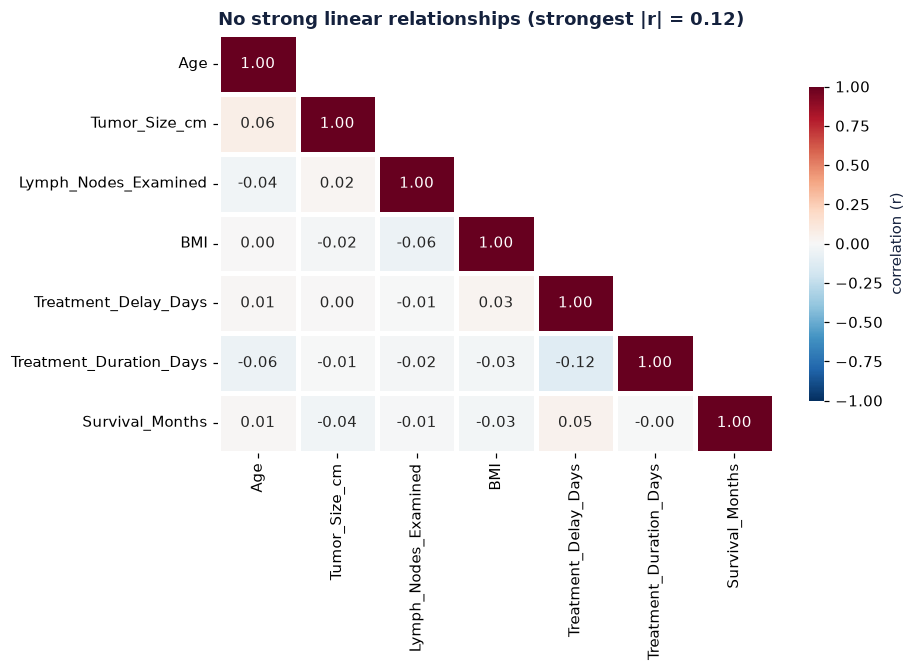

In [19]:
num = ['Age', 'Tumor_Size_cm', 'Lymph_Nodes_Examined', 'BMI', 'Treatment_Delay_Days', 'Treatment_Duration_Days', 'Survival_Months']
corr = clean[num].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
off = corr.where(~np.eye(len(corr), dtype=bool)).abs().max().max()
plt.figure(figsize=(8.5, 6.2))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor='white', cbar_kws={'shrink': .75, 'label': 'correlation (r)'})
plt.title(f'No strong linear relationships (strongest |r| = {off:.2f})', loc='left'); plt.grid(False)
plt.tight_layout(); save('05_correlation.png')

### Q5. Are the differences real? (statistical testing)
Bar charts always show *some* difference, because even random data is never perfectly equal. We need to ask whether a difference is **bigger than chance**.

- **Survival (a number) across groups** → Kruskal–Wallis test
- **Relapse (yes/no) across groups** → Chi-square test
- **p-value < 0.05** is the usual cut-off for "statistically significant". A large p-value means *"this could easily be chance"*.

In [20]:
FACTORS = ['Stage', 'Treatment_Type', 'Cancer_Type', 'Smoking_Status', 'Gender',
           'Family_History', 'Income_Level', 'BMI_Category', 'Age_Group']
rows = []
for f in FACTORS:
    p_s = stats.kruskal(*[x.Survival_Months.values for _, x in clean.groupby(f, observed=True)]).pvalue
    p_r = stats.chi2_contingency(pd.crosstab(clean[f], clean.Relapse))[1]
    rows.append((f, p_s, p_r))
pvals = pd.DataFrame(rows, columns=['Factor', 'p_survival', 'p_relapse']).set_index('Factor')
pvals.round(3)

,p_survival,p_relapse
Factor,,
Stage,0.204,0.686
Treatment_Type,0.393,0.735
Cancer_Type,0.211,0.260
Smoking_Status,0.888,0.154
Gender,0.239,0.182
Family_History,0.168,0.753
Income_Level,0.884,0.179
BMI_Category,0.162,0.191
Age_Group,0.994,0.833


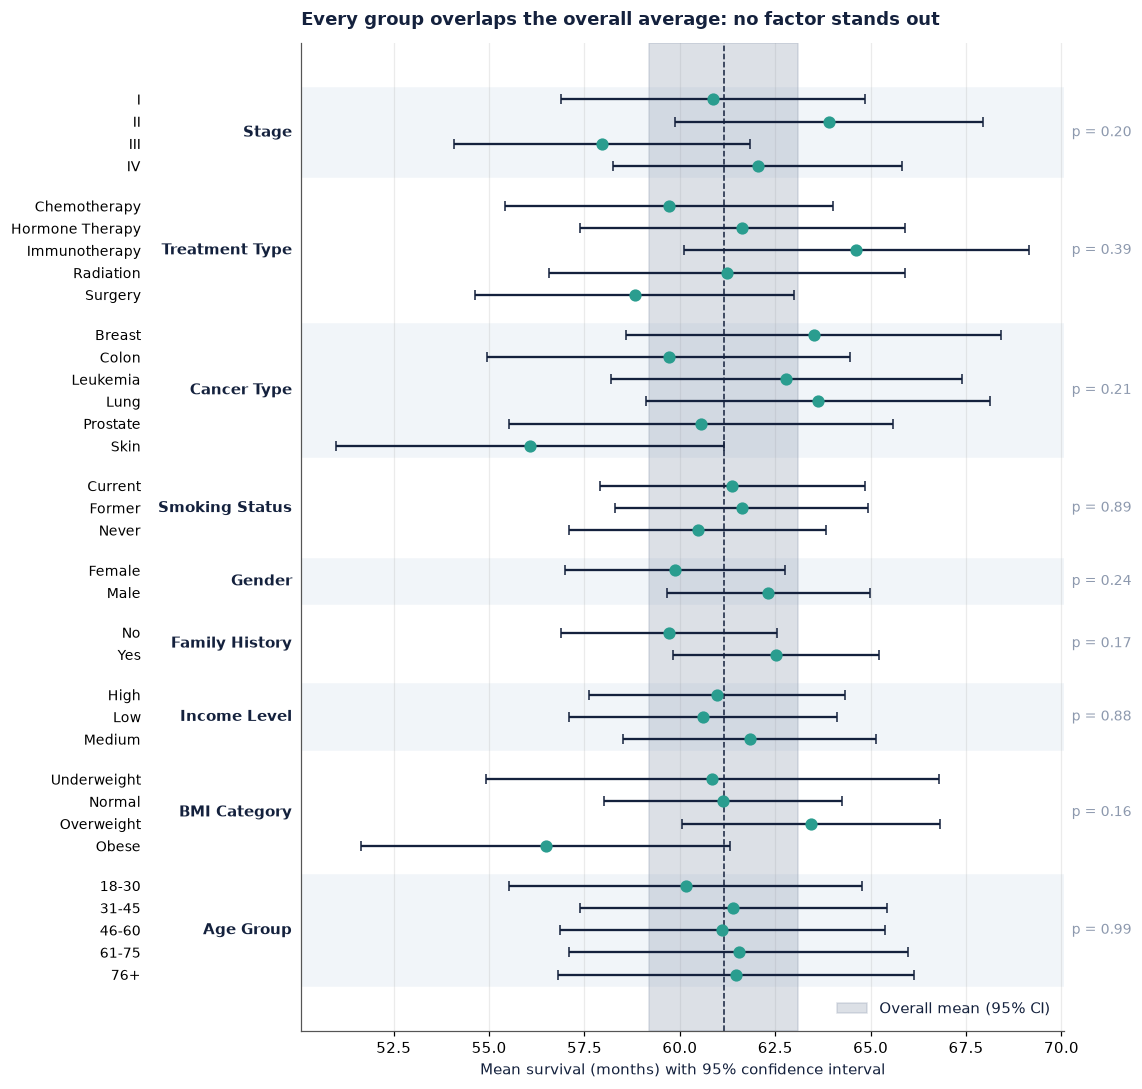

In [21]:
fig, ax = plt.subplots(figsize=(10.5, 10))
overall = clean.Survival_Months.mean(); _, olo, ohi = mean_ci(clean.Survival_Months)
ax.axvspan(olo, ohi, color=GREY, alpha=.3, label='Overall mean (95% CI)')
ax.axvline(overall, color=NAVY, ls='--', lw=1)
y, labels, pos = 0, [], []
for i, f in enumerate(FACTORS):
    cats = list(clean[f].cat.categories) if hasattr(clean[f], 'cat') else sorted(clean[f].unique())
    y0 = y
    for c in cats:
        m, lo, hi = mean_ci(clean.loc[clean[f] == c, 'Survival_Months'])
        ax.errorbar(m, y, xerr=[[m - lo], [hi - m]], fmt='o', color=TEAL, ecolor=NAVY, capsize=3, ms=7)
        labels.append(str(c)); pos.append(y); y += 1
    if i % 2 == 0: ax.axhspan(y0 - .5, y - .5, color='#F1F5F9', zorder=0)
    ax.text(-.012, (y0 + y - 1) / 2, f.replace('_', ' '), transform=ax.get_yaxis_transform(),
            ha='right', va='center', fontweight='bold', fontsize=10)
    ax.text(1.01, (y0 + y - 1) / 2, f'p = {pvals.loc[f, "p_survival"]:.2f}', transform=ax.get_yaxis_transform(), va='center', fontsize=9, color=GREY)
    y += .8
ax.set_yticks(pos); ax.set_yticklabels(labels, fontsize=9); ax.invert_yaxis(); ax.tick_params(axis='y', pad=105, length=0)
ax.grid(axis='y', visible=False)
ax.set_xlabel('Mean survival (months) with 95% confidence interval')
ax.set_title('Every group overlaps the overall average: no factor stands out', pad=12)
ax.legend(loc='lower right', frameon=False)
plt.tight_layout(); save('06_group_comparison.png')

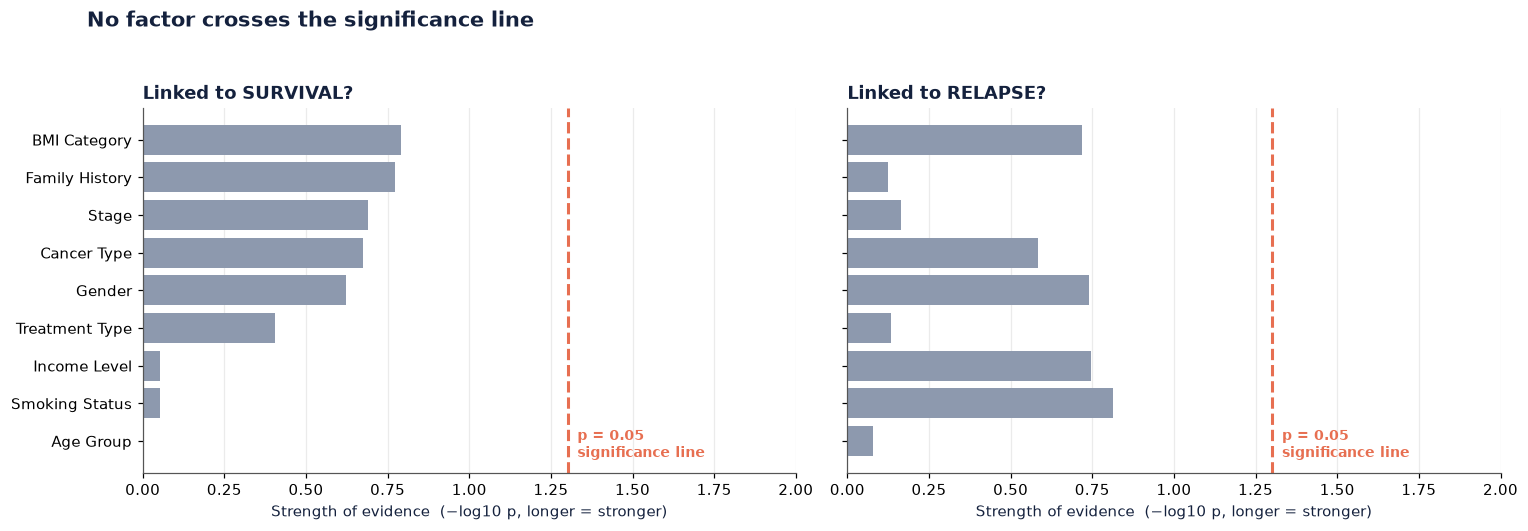

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
thr = -np.log10(.05)
for a_, col, ttl in zip(ax, ['p_survival', 'p_relapse'], ['Linked to SURVIVAL?', 'Linked to RELAPSE?']):
    v = (-np.log10(pvals[col])).sort_values()
    a_.barh([f.replace('_', ' ') for f in v.index], v.values, color=[TEAL if x > thr else GREY for x in v.values])
    a_.axvline(thr, color=CORAL, ls='--', lw=2); a_.set_xlim(0, max(2, v.max() * 1.1))
    a_.text(thr + .03, .03, 'p = 0.05\nsignificance line', color=CORAL, fontsize=9, fontweight='bold', transform=a_.get_xaxis_transform(), va='bottom')
    a_.set_title(ttl); a_.set_xlabel('Strength of evidence  (−log10 p, longer = stronger)'); a_.grid(axis='y', visible=False)
fig.suptitle('No factor crosses the significance line', x=.06, y=1.04, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout(); save('07_significance.png')

**Lesson:** none of the factors is statistically significant. Differences such as *"Obese patients average 56.5 months vs 61–63 for others"* look interesting on a bar chart but **can easily be chance**. A good analyst reports this honestly instead of inventing a story.

### Q6. Treatment delay: does waiting matter?
A median wait of about 20 months between diagnosis and treatment is far longer than in real clinics, which is another sign this is **synthetic practice data**.

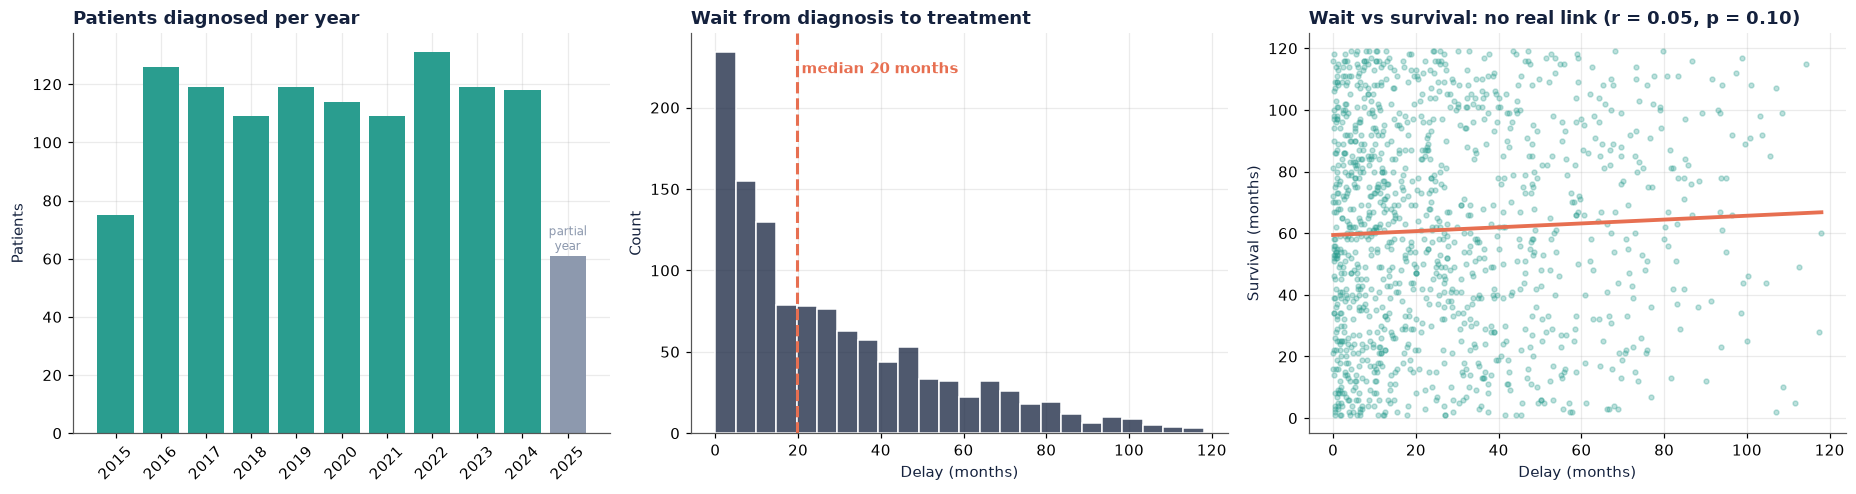

In [23]:
r_d, p_d = stats.pearsonr(clean.Treatment_Delay_Days, clean.Survival_Months)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
yr = clean.Diagnosis_Year.value_counts().sort_index()
ax[0].bar(yr.index.astype(str), yr.values, color=[TEAL] * (len(yr) - 1) + [GREY])
ax[0].set_title('Patients diagnosed per year'); ax[0].tick_params(axis='x', rotation=45); ax[0].set_ylabel('Patients')
ax[0].text(len(yr) - 1, yr.iloc[-1] + 2, 'partial\nyear', ha='center', fontsize=8, color=GREY)

dm = clean.Treatment_Delay_Days / 30.44
sns.histplot(dm, bins=24, color=NAVY, edgecolor='white', ax=ax[1])
ax[1].axvline(dm.median(), color=CORAL, ls='--', lw=2)
ax[1].text(dm.median() + 1, ax[1].get_ylim()[1] * .9, f'median {dm.median():.0f} months', color=CORAL, fontweight='bold')
ax[1].set_title('Wait from diagnosis to treatment'); ax[1].set_xlabel('Delay (months)')

ax[2].scatter(dm, clean.Survival_Months, s=10, alpha=.3, color=TEAL)
k, b = np.polyfit(dm, clean.Survival_Months, 1)
xs = np.linspace(dm.min(), dm.max(), 50); ax[2].plot(xs, k * xs + b, color=CORAL, lw=2.5)
ax[2].set_title(f'Wait vs survival: no real link (r = {r_d:.2f}, p = {p_d:.2f})')
ax[2].set_xlabel('Delay (months)'); ax[2].set_ylabel('Survival (months)')
plt.tight_layout(); save('08_treatment_timeline.png')

### Stage × cancer type: a deeper look

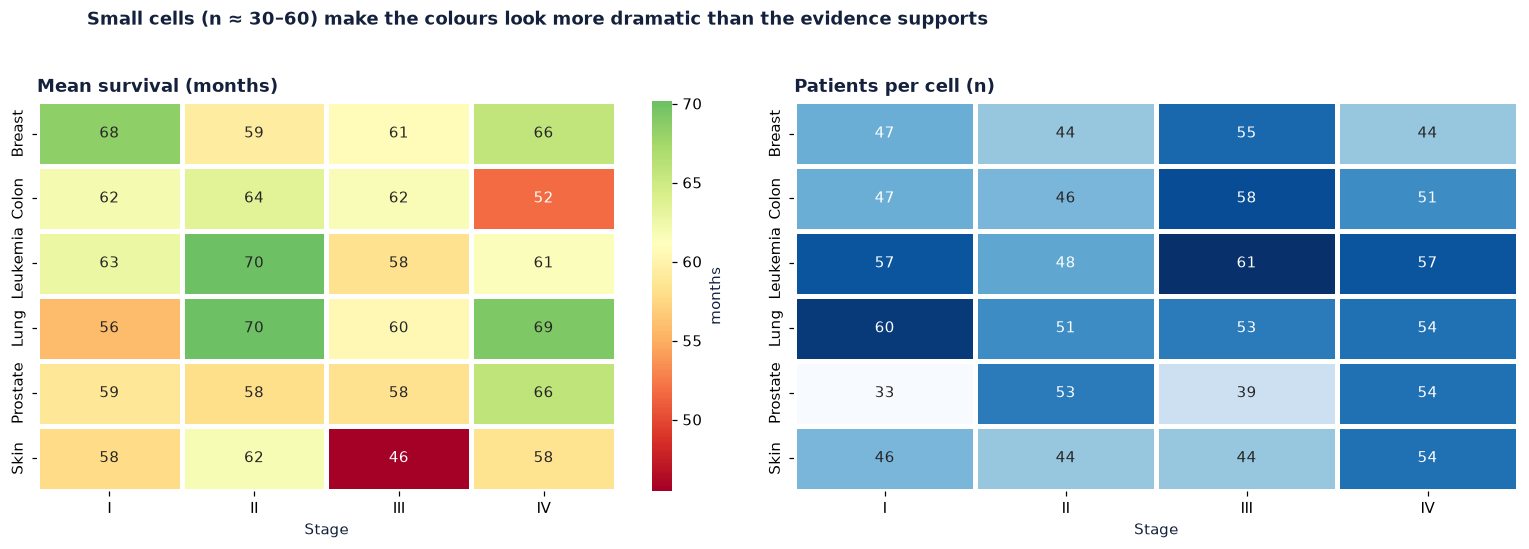

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
piv = clean.pivot_table(index='Cancer_Type', columns='Stage', values='Survival_Months', aggfunc='mean', observed=True)
sns.heatmap(piv, annot=True, fmt='.0f', cmap='RdYlGn', center=clean.Survival_Months.mean(), linewidths=2,
            linecolor='white', cbar_kws={'label': 'months'}, ax=ax[0])
ax[0].set_title('Mean survival (months)'); ax[0].set_ylabel('')
cnt = clean.pivot_table(index='Cancer_Type', columns='Stage', values='Patient_ID', aggfunc='count', observed=True)
sns.heatmap(cnt, annot=True, fmt='d', cmap='Blues', linewidths=2, linecolor='white', cbar=False, ax=ax[1])
ax[1].set_title('Patients per cell (n)'); ax[1].set_ylabel('')
fig.suptitle('Small cells (n ≈ 30–60) make the colours look more dramatic than the evidence supports', x=.06, y=1.03, ha='left', fontsize=12, fontweight='bold')
plt.tight_layout(); save('09_stage_cancer_heatmap.png')

### Q7. Which patients have short survival (< 24 months)?

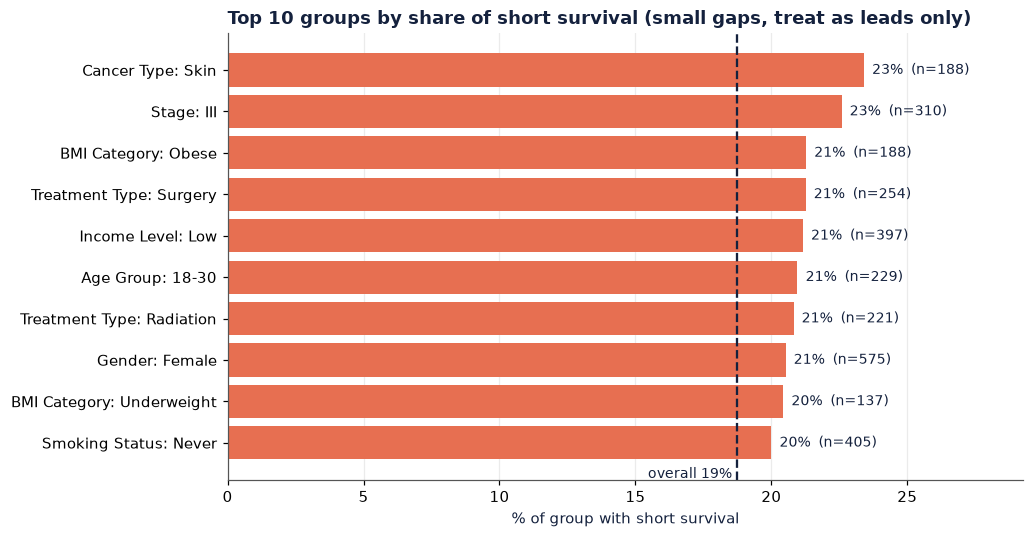

In [25]:
overall_short = (clean.Survival_Category == 'Short').mean()
rows = []
for f in FACTORS:
    for c, x in clean.groupby(f, observed=True):
        rows.append((f'{f.replace("_"," ")}: {c}', (x.Survival_Category == 'Short').mean(), len(x)))
sp = pd.DataFrame(rows, columns=['group', 'share', 'n']).sort_values('share', ascending=False).head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.barh(sp.group, sp.share * 100, color=[CORAL if s > overall_short else GREY for s in sp.share])
for i, (s, n) in enumerate(zip(sp.share, sp.n)): ax.text(s * 100 + .3, i, f'{s:.0%}  (n={n})', va='center', fontsize=9)
ax.axvline(overall_short * 100, color=NAVY, ls='--'); ax.text(overall_short * 100 - .2, -.85, f'overall {overall_short:.0%}', ha='right', fontsize=9)
ax.set_xlim(0, sp.share.max() * 100 * 1.25); ax.set_xlabel('% of group with short survival'); ax.grid(axis='y', visible=False)
ax.set_title('Top 10 groups by share of short survival (small gaps, treat as leads only)')
plt.tight_layout(); save('10_short_survival_groups.png')

## 7. Key insights (generated from the data)

In [26]:
sig = pvals[(pvals < .05).any(axis=1)]
best = clean.groupby('BMI_Category', observed=True).Survival_Months.mean()
print(f"1. {len(clean):,} patients · median age {clean.Age.median():.0f} · {clean.Gender.value_counts(normalize=True).iloc[0]:.0%} {clean.Gender.value_counts().index[0]}.")
print(f"2. Survival: {sh['Long']:.0%} Long · {sh['Medium']:.0%} Medium · {sh['Short']:.0%} Short (<24 months). Mean {clean.Survival_Months.mean():.1f} months.")
print(f"3. Relapse rate: {clean.Relapse_Flag.mean():.0%}.")
print(f"4. Lowest BMI group by survival: {best.idxmin()} ({best.min():.1f} months vs {best.max():.1f} best) - but p = {p_bmi_s:.2f}.")
print(f"5. Factors with a statistically significant link (p<0.05): {len(sig)} out of {len(FACTORS)}.")
print(f"6. Median wait for treatment: {dm.median():.0f} months; correlation with survival r = {r_d:.2f}.")
print(f"7. Data-quality warning: {checks.iloc[-1]} patients have survival longer than their follow-up window.")

1. 1,200 patients · median age 53 · 52% Male.
2. Survival: 52% Long · 30% Medium · 19% Short (<24 months). Mean 61.1 months.
3. Relapse rate: 48%.
4. Lowest BMI group by survival: Obese (56.5 months vs 63.4 best) - but p = 0.16.
5. Factors with a statistically significant link (p<0.05): 0 out of 9.
6. Median wait for treatment: 20 months; correlation with survival r = 0.05.
7. Data-quality warning: 698 patients have survival longer than their follow-up window.


## 8. Conclusions and recommendations
1. **No tested factor shows a reliable link to survival or relapse.** Stage, treatment, smoking, BMI, age, gender, income and family history all fail the significance test. Do not build a prediction model on these columns alone.
2. **Collect richer variables** (treatment response, comorbidities, genetic markers, cause of death) before any modelling.
3. **Resolve the follow-up inconsistency** with the data owner: survival time often exceeds the recorded follow-up window.
4. **Use the engineered columns** (`Age_Group`, `BMI_Category`, `Survival_Category`) in dashboards, since they are easier to read than raw numbers.
5. **Report uncertainty, not just averages.** Confidence intervals and p-values keep a team from acting on noise.

### Limitations
Practice dataset · rows with missing values removed (14) · cross-sectional associations, not causes · survival may include censoring that this file does not record.